# Лабораторная работа 5. Ассоциативные правила и кластеризация (методы обучения без учителя)


Структура датасета (датасет содержит 27 переменных, которые можно 
разделить на несколько групп):
1. Идентификаторы и базовые характеристики

    - id — уникальный номер выпускника
    - year_graduation — год выпуска (2018–2025)
    - region — федеральный округ
    - city_type — тип города (мегаполис / областной центр / малый город)
    - university_type — тип вуза (национальный исследовательский / классический / отраслевой)
2. Образовательные характеристики
    - it_direction — IT-направление (разработка / аналитика / бизнес-информатика)
    - specialization — узкая специализация внутри направления
    - degree — уровень образования (бакалавр / специалист / магистр)
    - exam_math, exam_russian, exam_informatics — баллы ЕГЭ по предметам
    - exam_total — суммарный балл ЕГЭ
    - gpa — средний балл диплома (GPA, от 3.0 до 5.0)
    - gpa_relative — место в рейтинге группы (в процентах)
3. Опыт и навыки
    - has_github — наличие публичного портфолио/GitHub (1 — да, 0 — нет)
    - github_quality — качество портфолио (базовое / продвинутое)
    - internship — наличие стажировки в IT (1 — да, 0 — нет)
    - internship_company_type — тип компании стажировки (BigTech / стартап /
    аутсорс)
    - internship_field — соответствие стажировки специальности 
    (по_специальности / не_по_специальности)
4. Карьерные траектории
    - employment_status — статус через 6 месяцев после выпуска (работает
    по специальности / работает не по специальности / учится дальше /
    не работает)
    - first_salary — первая зарплата (руб/мес)
    - salary_in_field — зарплата выше средней по региону? (1 — да, 0 — нет)
    - job_search_time — время поиска работы (месяцев, от 0 до 18)
    - has_job_offer_before_graduation — предложение работы до выпуска (1 —
    да, 0 — нет)
    - expectation_salary — ожидаемая зарплата до выпуска (руб/мес)
5. Демография
    - gender — пол (М / Ж)
    - age_at_graduation — возраст на момент выпуска

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import gdown

In [2]:
df = pd.read_csv("Unis.csv", sep = ";")

df.head()
print(df.isna().sum())

id                                    0
year_graduation                       0
region                                0
city_type                             0
university_type                       0
it_direction                          0
specialization                        0
degree                                0
exam_math                           857
exam_russian                        925
exam_informatics                   1020
exam_total                            0
gpa                                 913
gpa_relative                        941
has_github                            0
github_quality                      973
internship                            0
internship_company_type            4618
internship_field                   5055
employment_status                  1012
first_salary                        925
salary_in_field                     988
job_search_time                    1012
gender                                0
age_at_graduation                     0


## Чистка данных

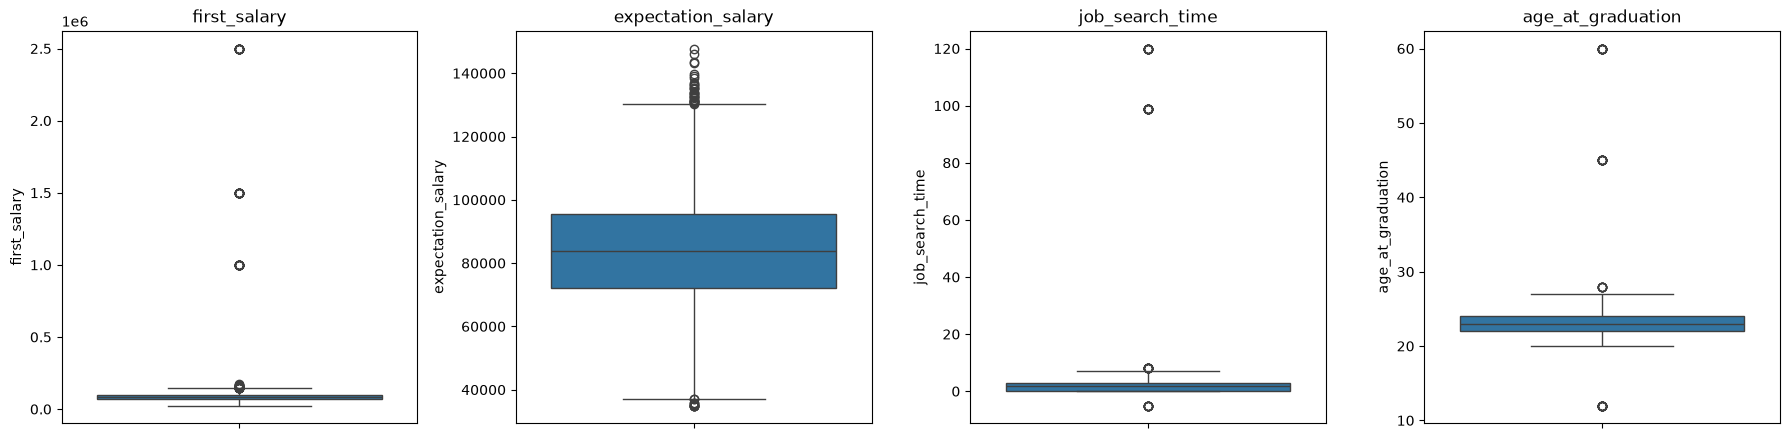

,count,mean,std,min,25%,50%,75%,max
first_salary,7724.0,93448.989125,130830.775191,25000.0,68899.5,83698.0,99549.5,2500000.0
expectation_salary,7657.0,83954.797048,17266.332920,35000.0,72084.0,83708.0,95377.0,147804.0
job_search_time,7637.0,2.365981,6.359371,-5.0,0.0,2.0,3.0,120.0
age_at_graduation,8649.0,22.744710,2.172550,12.0,22.0,23.0,24.0,60.0


In [3]:
out_cols = ['first_salary', 'expectation_salary', 'job_search_time', 'age_at_graduation']

fig, axes = plt.subplots(1, 4, figsize = (18, 4.5))
for ax, col in zip(axes, out_cols):
    sns.boxplot(y = df[col], ax = ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

df[out_cols].describe().T

У `expectation_salary` хвост адекватный: от 35 до 148 тыс. руб., выбросы по IQR лежат рядом с усами. Оставляю как есть.

В остальных трёх признаках есть ошибки ввода:

- `job_search_time`: значения 99 и 120 месяцев, хотя по описанию шкала от 0 до 18, и −5 месяцев.
- `age_at_graduation`: выпускники 12, 45 и 60 лет при среднем 22.7.
- `first_salary`: 999 999, 1.5 млн и 2.5 млн руб. при медиане около 84 тыс. Между ними и нормальными зарплатами разрыв: следующее значение около 175 тыс. Порог беру 300 тыс. 99.5-й перцентиль здесь не подходит, он равен 999 999 и оставил бы эти строки. Правило 1.5·IQR (граница около 145 тыс.) срезало бы ещё 30 обычных зарплат 145–175 тыс.

Без фильтра k-means тратит отдельные кластеры на эти точки: при k = 5 три кластера из 25, 48 и 22 человек собраны вокруг поиска работы 108 месяцев, зарплаты 1.6 млн и возраста 52 года. Удаляю такие строки до заполнения пропусков, чтобы мусор не попал в медиану.

In [4]:
bad = (
    (df['job_search_time'] < 0) | (df['job_search_time'] > 18)
    | (df['age_at_graduation'] < 19) | (df['age_at_graduation'] > 35)
    | (df['first_salary'] > 300_000)
)
print(f'Удаляю {bad.sum()} строк ({bad.mean():.1%} данных)')

df = df[~bad].reset_index(drop = True)
print(df.shape)

Удаляю 119 строк (1.4% данных)
(8530, 27)


In [5]:
df['gpa'] = df['gpa'].str.replace(',', '.').astype(float)

for col in ['internship_company_type', 'internship_field']:
    df.loc[df['internship'] == 0, col] = 'нет_стажировки'
    df[col] = df[col].fillna('неизвестно')

df.loc[df['has_github'] == 0, 'github_quality'] = 'нет_github'
df['github_quality'] = df['github_quality'].fillna('неизвестно')

df['employment_status'] = df['employment_status'].fillna('неизвестно')

num_cols = ['exam_math', 'exam_russian', 'exam_informatics', 'gpa', 'gpa_relative',
            'first_salary', 'expectation_salary', 'job_search_time']
print('Доля пропусков, %:')
print((df[num_cols].isna().mean() * 100).round(1))
print(f'Удаление строк с пропусками стоило бы {1 - len(df.dropna(subset = num_cols)) / len(df):.0%} данных')

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print(df.isna().sum()[df.isna().sum() > 0])

Доля пропусков, %:
exam_math              9.8
exam_russian          10.7
exam_informatics      11.8
gpa                   10.6
gpa_relative          10.9
first_salary          10.7
expectation_salary    11.5
job_search_time       11.7
dtype: float64
Удаление строк с пропусками стоило бы 60% данных
salary_in_field    980
dtype: int64


Пропусков в числовых признаках около 10% в каждом, и они случайные. Удаление строк с пропусками стоило бы около 60% данных, поэтому заполняю медианой.

### Kластеризация

In [6]:
from sklearn.preprocessing import StandardScaler
import numpy as np

features = [
    'exam_total', 'gpa', 'gpa_relative', 
    'first_salary', 'expectation_salary', 
    'job_search_time', 'age_at_graduation']

student_ids = df['id']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)



Text(0, 0.5, 'Число силуэта')

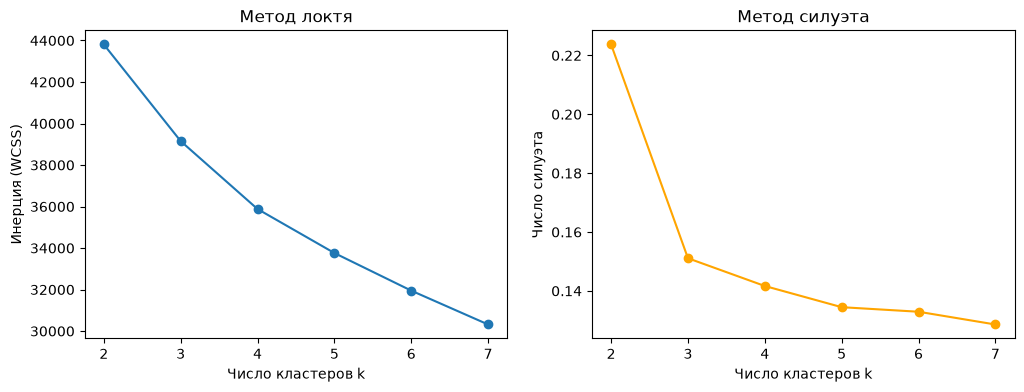

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette = []
K_range = range(2, 8)

for k in K_range: 
    kmeans = KMeans(n_clusters=k, random_state=42, n_init = 10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X_scaled, kmeans.labels_))

fig, axes = plt.subplots(1, 2, figsize = (12, 4))


axes[0].plot(K_range, inertia, marker = 'o')
axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Число кластеров k')
axes[0].set_ylabel('Инерция (WCSS)')

axes[1].plot(K_range, silhouette, marker='o', color='orange')
axes[1].set_title('Метод силуэта')
axes[1].set_xlabel('Число кластеров k')
axes[1].set_ylabel('Число силуэта')

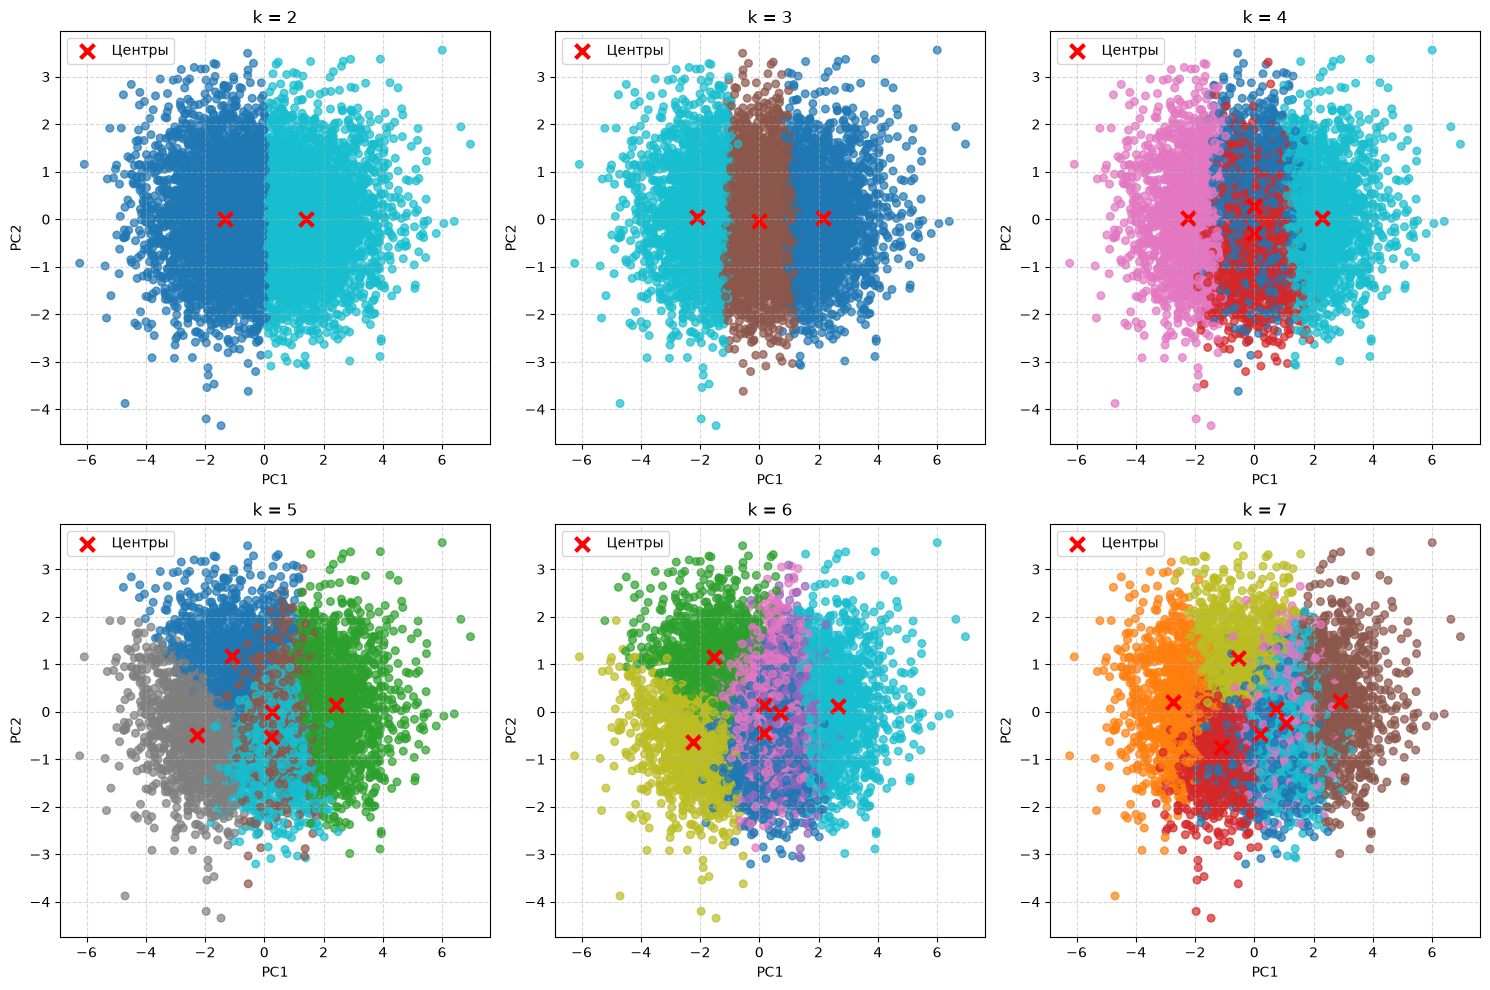

In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

k_range = range(2, 8)
models = {}

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    models[k] = km

plt.figure(figsize=(15, 10))

for i, k in enumerate(k_range):

    kmeans_model = models[k]
    labels = kmeans_model.labels_
    centers = kmeans_model.cluster_centers_

    centers_pca = pca.transform(centers)
    plt.subplot(2, 3, i + 1)
    plt.scatter(
        X_pca[:, 0], X_pca[:, 1], c=labels, cmap = 'tab10', s = 30, alpha=0.7
    )

    plt.scatter(
        centers_pca[:, 0],
        centers_pca[:, 1],
        c='red',
        marker='x',
        s=100,
        linewidths=3,
        label='Центры',
    )

    plt.title(f'k = {k}')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()

plt.tight_layout()
plt.show()

In [9]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

cluster_profiles = df.groupby('Cluster')[features].mean()
cluster_profiles['Count'] = df['Cluster'].value_counts()
cluster_profiles['Percent'] = (
    df['Cluster'].value_counts(normalize=True) * 100
)

display(cluster_profiles)

,exam_total,gpa,gpa_relative,first_salary,expectation_salary,job_search_time,age_at_graduation,Count,Percent
Cluster,,,,,,,,,
0,208.179911,3.688732,71.887054,66673.985268,68955.452679,3.450893,22.727232,2240,26.260258
1,224.742112,4.005173,59.325714,83225.526211,83447.174907,1.741863,22.688447,4025,47.186401
2,240.081236,4.354018,45.906843,102156.587196,99332.560265,1.111700,22.636645,2265,26.553341


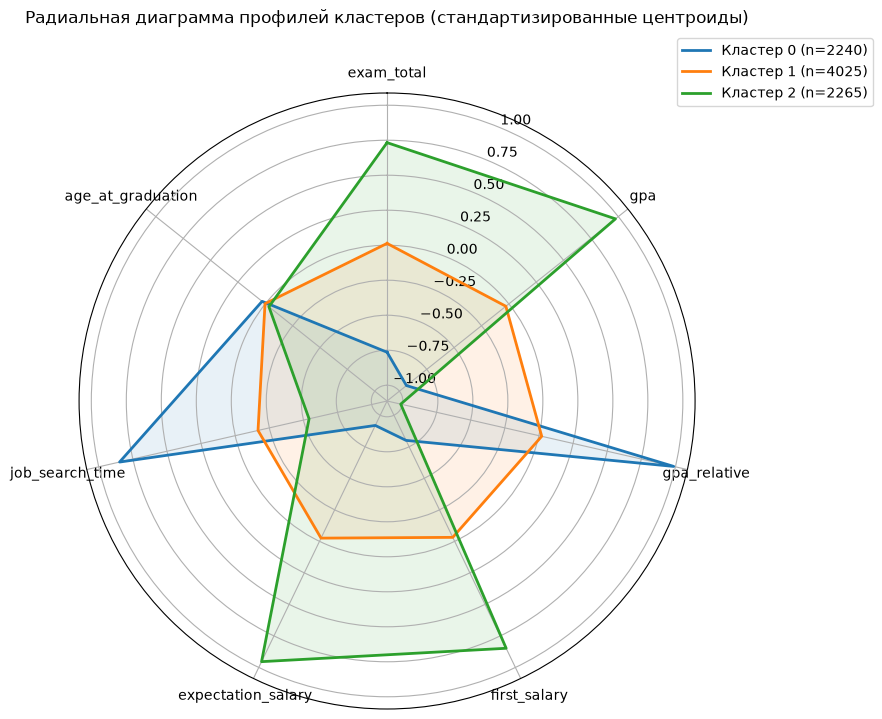

In [10]:
cluster_scaled_profiles = X_scaled_df.copy()
cluster_scaled_profiles['Cluster'] = df['Cluster']
mean_profiles = cluster_scaled_profiles.groupby('Cluster').mean()

labels = features
num_vars = len(labels)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for i, row in mean_profiles.iterrows():
    values = row.values.tolist()
    values += values[:1]
    ax.plot(
        angles,
        values,
        linewidth = 2,
        label=f'Кластер {i} (n={cluster_profiles.loc[i, "Count"]})'
        )
    ax.fill(angles, values, alpha=0.1)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)

plt.title(
    'Радиальная диаграмма профилей кластеров (стандартизированные центроиды)',
    size=12,
    y=1.1,
)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

### Вывод
- Кластер 2 (зелёный, 27%): «высокобальники». ЕГЭ и GPA сильно выше среднего, зарплата и ожидания высокие, поиск работы быстрый, gpa_relative низкий (то есть высокое место в рейтинге).
- Кластер 1 (оранжевый, 47%): «середина». Всё около нуля, чуть ниже среднего.
- Кластер 0 (синий, 26%): «слабые и долго ищущие». Самые низкие ЕГЭ и GPA, самая низкая зарплата, а поиск работы самый долгий и gpa_relative самый высокий (хуже всех в рейтинге).

Возраст одинаков у всех, ось «возраст» ничего не различает. Это подтверждает, что признак можно спокойно убрать.

Ожидания vs зарплата: у звёзд ожидания заметно выше среднего, но по форме фигуры совпадают с реальной зарплатой, значит, разрыва в среднем нет.

### Выделение особых случаев в данных используя метод Apriori

In [11]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,8530.0,4322.025557,2496.518038,1.0,2162.25,4320.50,6481.75,8649.0
year_graduation,8530.0,2021.908441,1.959596,2018.0,2021.00,2022.00,2023.00,2025.0
exam_math,8530.0,78.360844,13.627600,0.0,71.00,78.00,85.00,200.0
exam_russian,8530.0,71.825088,9.361057,35.0,66.00,72.00,78.00,100.0
exam_informatics,8530.0,74.729074,13.860454,20.0,66.00,75.00,84.00,100.0
exam_total,8530.0,224.465885,21.310287,131.0,210.00,225.00,239.00,297.0
gpa,8530.0,4.014705,0.348364,1.2,3.82,4.01,4.20,6.5
gpa_relative,8530.0,59.061196,12.990080,11.0,51.00,59.00,67.00,99.0
has_github,8530.0,0.550293,0.497493,0.0,0.00,1.00,1.00,1.0
internship,8530.0,0.465651,0.498848,0.0,0.00,0.00,1.00,1.0


In [13]:
cat_cols = ['it_direction', 'university_type', 
        'city_type', 'degree', 'github_quality', 
        'internship_company_type', 'internship_field'        
        ]
num_cols = ['gpa', 'first_salary', 'job_search_time']

Apriori работает с транзакциями, поэтому каждого выпускника переделываю в «чек» из признаков. Числовые признаки режу на группы, категориальные через one-hot, бинарные беру как есть.

In [14]:
data_for_apriori = pd.DataFrame(index = df.index)

data_for_apriori['gpa_низкий'] = df['gpa'] < 3.8
data_for_apriori['gpa_высокий'] = df['gpa'] >= 4.3

salary_q75 = df['first_salary'].quantile(0.75)
data_for_apriori['зп_высокая'] = df['first_salary'] >= salary_q75
data_for_apriori['зп_низкая'] = df['first_salary'] < df['first_salary'].quantile(0.25)

data_for_apriori['поиск_быстрый'] = df['job_search_time'] <= 1
data_for_apriori['поиск_долгий'] = df['job_search_time'] >= 4

data_for_apriori['github'] = df['has_github'] == 1
data_for_apriori['стажировка'] = df['internship'] == 1
data_for_apriori['оффер_до_выпуска'] = df['has_job_offer_before_graduation'] == 1

data_for_apriori = data_for_apriori.join(pd.get_dummies(df[cat_cols], prefix_sep = '=').astype(bool))

print('Порог высокой зарплаты:', salary_q75)
print(data_for_apriori.shape)
data_for_apriori.mean().sort_values(ascending = False).round(2)

Порог высокой зарплаты: 97047.5
(8530, 33)


github                                            0.55
degree=бакалавр                                   0.54
internship_company_type=нет_стажировки            0.53
internship_field=нет_стажировки                   0.53
оффер_до_выпуска                                  0.53
стажировка                                        0.47
city_type=областной_центр                         0.46
it_direction=разработка                           0.45
github_quality=нет_github                         0.45
university_type=классический                      0.40
поиск_быстрый                                     0.39
university_type=национальный_исследовательский    0.36
it_direction=аналитика                            0.35
internship_field=по_специальности                 0.31
github_quality=базовое                            0.29
city_type=мегаполис                               0.29
city_type=малый_город                             0.25
degree=специалист                                 0.25
зп_высокая

In [ ]:
frequent_itemsets = apriori(data_for_apriori, min_support = 0.05, use_colnames = True, max_len = 4)
rules = association_rules(frequent_itemsets, metric = 'confidence', min_threshold = 0.3)

selected_rules = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
print(len(frequent_itemsets), len(selected_rules))

def show(r):
    r = r.copy()
    r['antecedents'] = r['antecedents'].apply(lambda x: ', '.join(sorted(x)))
    r['consequents'] = r['consequents'].apply(lambda x: ', '.join(sorted(x)))
    return r.round(3)

1667 6521


Строю 3 набора правил, в каждом свой главный фильтр:

- по Support: support ≥ 0.25 и confidence ≥ 0.5
- по Confidence: support ≥ 0.05 и confidence ≥ 0.85
- по Lift: support ≥ 0.05 и lift ≥ 2

In [16]:
rules_support = selected_rules[(selected_rules['support'] >= 0.25) & (selected_rules['confidence'] >= 0.5)]
rules_conf = selected_rules[(selected_rules['support'] >= 0.05) & (selected_rules['confidence'] >= 0.85)]
rules_lift = selected_rules[(selected_rules['support'] >= 0.05) & (selected_rules['lift'] >= 2)]

print('Support:', len(rules_support), ' Confidence:', len(rules_conf), ' Lift:', len(rules_lift))

Support: 52  Confidence: 581  Lift: 1036


In [17]:
display(show(rules_support.sort_values('support', ascending = False).head(5)))
display(show(rules_conf.sort_values('confidence', ascending = False).head(5)))
display(show(rules_lift.sort_values('lift', ascending = False).head(5)))

,antecedents,consequents,support,confidence,lift
389,internship_field=нет_стажировки,internship_company_type=нет_стажировки,0.534,1.000,1.871
388,internship_company_type=нет_стажировки,internship_field=нет_стажировки,0.534,1.000,1.871
115,оффер_до_выпуска,github,0.375,0.709,1.288
116,github,оффер_до_выпуска,0.375,0.682,1.288
151,стажировка,оффер_до_выпуска,0.341,0.731,1.381


,antecedents,consequents,support,confidence,lift
6516,"degree=специалист, github_quality=нет_github, ...",internship_company_type=нет_стажировки,0.077,1.0,1.871
6514,"degree=специалист, github_quality=нет_github, ...",internship_field=нет_стажировки,0.077,1.0,1.871
6509,"degree=магистр, github_quality=нет_github, int...",internship_company_type=нет_стажировки,0.065,1.0,1.871
6427,"city_type=мегаполис, github_quality=нет_github...",internship_field=нет_стажировки,0.091,1.0,1.871
6426,"city_type=мегаполис, github_quality=нет_github...",internship_company_type=нет_стажировки,0.091,1.0,1.871


,antecedents,consequents,support,confidence,lift
5431,"github, internship_company_type=нет_стажировки","github_quality=продвинутое, internship_field=н...",0.079,0.357,4.494
5432,"github, internship_field=нет_стажировки","github_quality=продвинутое, internship_company...",0.079,0.357,4.494
5434,"github_quality=продвинутое, internship_field=н...","github, internship_company_type=нет_стажировки",0.079,1.000,4.494
5433,"github_quality=продвинутое, internship_company...","github, internship_field=нет_стажировки",0.079,1.000,4.494
5423,"github_quality=базовое, internship_company_typ...","github, internship_field=нет_стажировки",0.119,1.000,4.494


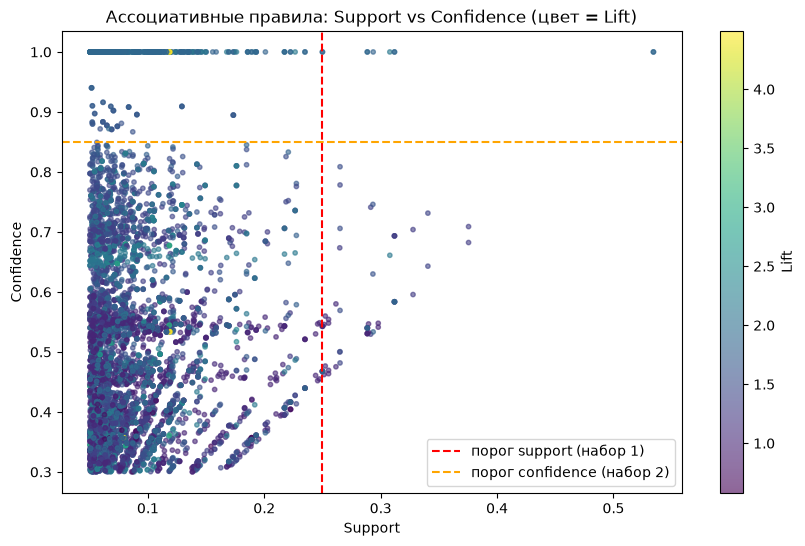

In [18]:
plt.figure(figsize = (10, 6))

scatter = plt.scatter(
    selected_rules['support'],
    selected_rules['confidence'],
    c = selected_rules['lift'],
    cmap = 'viridis',
    s = 10,
    alpha = 0.6,
)

cbar = plt.colorbar(scatter)
cbar.set_label('Lift')

plt.axvline(0.25, color = 'red', linestyle = '--', label = 'порог support (набор 1)')
plt.axhline(0.85, color = 'orange', linestyle = '--', label = 'порог confidence (набор 2)')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Ассоциативные правила: Support vs Confidence (цвет = Lift)')
plt.legend()
plt.show()

In [19]:
outcomes = ('зп_', 'поиск_', 'employment_status')

def rules_for(target):
    r = selected_rules[selected_rules['consequents'] == frozenset({target})]
    r = r[~r['antecedents'].apply(lambda s: any(x.startswith(outcomes) for x in s))]
    return r[r['lift'] > 1.2]

for target in ['зп_высокая', 'поиск_быстрый']:
    r = rules_for(target)
    print(target, 'правил:', len(r))
    for metric in ['support', 'confidence', 'lift']:
        print('топ-5 по', metric)
        display(show(r.sort_values(metric, ascending = False).head(5)))

зп_высокая правил: 50
топ-5 по support


,antecedents,consequents,support,confidence,lift
36,github,зп_высокая,0.172,0.312,1.247
40,it_direction=разработка,зп_высокая,0.171,0.378,1.513
592,"github, оффер_до_выпуска",зп_высокая,0.121,0.322,1.288
596,"github, it_direction=разработка",зп_высокая,0.116,0.443,1.773
588,"github, стажировка",зп_высокая,0.105,0.321,1.284


топ-5 по confidence


,antecedents,consequents,support,confidence,lift
493,"gpa_высокий, it_direction=разработка",зп_высокая,0.062,0.522,2.086
485,"github, gpa_высокий",зп_высокая,0.056,0.506,2.023
683,"city_type=мегаполис, it_direction=разработка",зп_высокая,0.063,0.495,1.981
489,"gpa_высокий, оффер_до_выпуска",зп_высокая,0.051,0.492,1.966
3025,"github, it_direction=разработка, оффер_до_выпуска",зп_высокая,0.083,0.456,1.824


топ-5 по lift


...

,antecedents,consequents,support,confidence,lift
72,стажировка,поиск_быстрый,0.293,0.630,1.602
70,github,поиск_быстрый,0.291,0.530,1.347
74,оффер_до_выпуска,поиск_быстрый,0.265,0.500,1.272
846,"github, стажировка",поиск_быстрый,0.228,0.694,1.766
77,it_direction=разработка,поиск_быстрый,0.222,0.493,1.253


топ-5 по confidence


,antecedents,consequents,support,confidence,lift
2839,"github, gpa_высокий, стажировка",поиск_быстрый,0.057,0.828,2.106
2868,"gpa_высокий, it_direction=разработка, стажировка",поиск_быстрый,0.053,0.821,2.088
2861,"gpa_высокий, оффер_до_выпуска, стажировка",поиск_быстрый,0.056,0.804,2.044
498,"gpa_высокий, стажировка",поиск_быстрый,0.072,0.798,2.030
3894,"github_quality=базовое, it_direction=разработк...",поиск_быстрый,0.065,0.788,2.004


топ-5 по lift


,antecedents,consequents,support,confidence,lift
2839,"github, gpa_высокий, стажировка",поиск_быстрый,0.057,0.828,2.106
2868,"gpa_высокий, it_direction=разработка, стажировка",поиск_быстрый,0.053,0.821,2.088
2861,"gpa_высокий, оффер_до_выпуска, стажировка",поиск_быстрый,0.056,0.804,2.044
498,"gpa_высокий, стажировка",поиск_быстрый,0.072,0.798,2.030
3894,"github_quality=базовое, it_direction=разработк...",поиск_быстрый,0.065,0.788,2.004


### Как меняется ТОП-5 в зависимости от метрики

**Общие наборы.**
- По support наверху самые частые признаки. Связка github  оффер_до_выпуска (support 0.375, confidence 0.68–0.71) логичная: у кого есть портфолио, тому чаще предлагают работу до выпуска.
- По confidence все пять правил с confidence = 1.0, и все про одно и то же: нет стажировки в `internship_field` нет стажировки в `internship_company_type`. Это один и тот же факт в двух колонках, я сам так заполнил пропуски. Правило верное, но пользы от него ноль.
- По lift наверху lift 4.49, и это опять та же связка, только с github. Lift большой, потому что сочетание редкое, а не потому что нашлась связь.

**Правила с результатом справа.**
- По support вылезают широкие, но слабые правила: github  зп_высокая, confidence 0.31 при базовых 0.25, lift 1.25. Правило подходит многим и почти ничего не говорит.
- По confidence и по lift ТОП-5 совпадает полностью. Так и должно быть: правая часть у всех одна, а lift = confidence / support(зп_высокая), делим на одно и то же число.
- Самые логичные: gpa_высокий + разработка → зп_высокая (52% против 25% в среднем, lift 2.09) и gpa_высокий + стажировка поиск_быстрый (80% против 39%, lift 2.03). Хорошо учился и уже работал, значит, берут быстрее и платят больше.
- Странно выглядит стажировка в BigTech: в профиле ниже у разработчиков и аналитиков её lift (1.28 и 1.34) ниже, чем у стажировки в стартапе или аутсорсе (1.61–1.90). Возможно, после стажировки в BigTech выпускник часто остаётся там на позиции стажёра или джуна с невысокой зарплатой, а может, так устроены сами данные.

### Профиль «идеального кандидата»

Успешный выпускник для меня: зарплата в верхних 25% внутри своего направления и работа найдена за месяц или быстрее. Порог считаю по направлению, потому что у разработчиков зарплаты выше и при общем пороге аналитики почти не попадали бы в успешные.

Дальше для каждого фактора смотрю два правила:

- успех = фактор: у какой доли успешных этот фактор есть. Если >= 0.8, фактор обязательный, без него успешных почти нет.
- фактор = успех: lift, во сколько раз фактор повышает шанс. Если lift >= 1.2, а обязательным фактор не стал, значит желательный.

In [20]:
q75_dir = df.groupby('it_direction')['first_salary'].transform(lambda s: s.quantile(0.75))
df['success'] = (df['first_salary'] >= q75_dir) & (df['job_search_time'] <= 1)
print('Доля успешных:', round(df['success'].mean(), 3))

factor_cols = [c for c in data_for_apriori.columns if not c.startswith(outcomes + ('it_direction',)) and 'неизвестно' not in c]

profiles = {}
for direction in ['разработка', 'аналитика', 'бизнес-информатика']:
    mask = df['it_direction'] == direction
    f = data_for_apriori.loc[mask, factor_cols]
    s = df.loc[mask, 'success']

    conf_success_factor = f[s].mean()           # успех -> фактор
    lift = f[s].mean() / f.mean()                # = conf(фактор -> успех) / P(успех)

    profiles[direction] = pd.DataFrame({'conf(успех→фактор)': conf_success_factor, 'lift': lift})

profile = pd.concat(profiles, axis = 1)
profile = profile[(profile.xs('lift', axis = 1, level = 1) >= 1.2).any(axis = 1)]
profile.sort_values(('разработка', 'lift'), ascending = False).round(2)

Доля успешных: 0.117


разработка        \
                                     conf(успех→фактор)  lift   
gpa_высокий                                        0.49  1.84   
internship_company_type=аутсорс                    0.23  1.63   
internship_company_type=стартап                    0.31  1.61   
internship_field=по_специальности                  0.49  1.56   
github_quality=продвинутое                         0.31  1.53   
стажировка                                         0.73  1.52   
github                                             0.81  1.40   
github_quality=базовое                             0.43  1.40   
city_type=мегаполис                                0.39  1.38   
internship_field=не_по_специальности               0.14  1.32   
internship_company_type=BigTech                    0.19  1.28   
оффер_до_выпуска                                   0.71  1.26   
degree=специалист                                  0.27  1.08   

                                              аналитика        \
                                     conf(успех→фактор)  lift   
gpa_высокий                                        0.24  2.26   
internship_company_type=аутсорс                    0.27  1.90   
internship_company_type=стартап                    0.34  1.77   
internship_field=по_специальности                  0.52  1.70   
github_quality=продвинутое                         0.28  1.46   
стажировка                                         0.79  1.69   
github                                             0.82  1.51   
github_quality=базовое                             0.44  1.51   
city_type=мегаполис                                0.42  1.48   
internship_field=не_по_специальности               0.17  1.63   
internship_company_type=BigTech                    0.18  1.34   
оффер_до_выпуска                                   0.72  1.42   
degree=специалист                                  0.26  1.06   

                                     бизнес-информатика        
                                     conf(успех→фактор)  lift  
gpa_высокий                                        0.18  2.55  
internship_company_type=аутсорс                    0.25  1.85  
internship_company_type=стартап                    0.26  1.55  
internship_field=по_специальности                  0.53  1.87  
github_quality=продвинутое                         0.32  1.83  
стажировка                                         0.76  1.77  
github                                             0.84  1.68  
github_quality=базовое                             0.42  1.57  
city_type=мегаполис                                0.40  1.36  
internship_field=не_по_специальности               0.20  1.86  
internship_company_type=BigTech                    0.25  1.95  
оффер_до_выпуска                                   0.77  1.54  
degree=специалист                                  0.33  1.27

In [ ]:
lift_table = profile.xs('lift', axis = 1, level = 1).sort_values('разработка', ascending = False)

plt.figure(figsize = (8, 7))
sns.heatmap(lift_table, annot = True, fmt = '.2f', cmap = 'RdYlGn', center = 1)
plt.title('Lift правила «фактор = успех» по направлениям')
plt.show()

NameError: name 'profile' is not defined

### Вывод по профилю

- Обязательный фактор один: GitHub. Он есть у 81-84% успешных во всех трёх направлениях. Стажировка почти обязательная: 73-79% успешных её проходили.
- Желательные: GPA >= 4.3 (самый большой lift, 1.84–2.55), стажировка по специальности, оффер до выпуска (есть у 71–77% успешных), продвинутый GitHub, мегаполис.
- Портрет: есть GitHub, лучше продвинутый, была стажировка по специальности, оффер получил ещё до выпуска, GPA от 4.3, живёт в мегаполисе.

Чем отличаются направления:
- Разработка: высокий GPA есть у половины успешных (0.49), но lift у него самый низкий из трёх (1.84). Средние зарплаты у разработчиков и так выше, хорошие оценки тут скорее норма.
- Аналитика: высокий GPA есть только у 24% успешных, зато шанс он поднимает в 2.26 раза. Стажировка важнее, чем у разработчиков (79% успешных, lift 1.69).
- Бизнес-информатика: GPA даёт самый большой прирост (lift 2.55), хотя высокий GPA только у 18% успешных. Только здесь заметно помогает стажировка в BigTech (1.95) и степень специалиста (1.27).

### Общий вывод

- k-means при k = 3 разделил выпускников на три уровня: «слабые», «середина» и «высокобальники». Признаки растут вместе, поэтому кластеры получились ступеньками. Плюс в том, что сразу видно, сколько людей в каждой группе и насколько отличаются зарплата и время поиска. Минус в том, что зарплата и время поиска сами стоят в признаках, и кластеры не говорят, что именно на них влияет.
- Apriori отвечает как раз на это: какие сочетания признаков чаще дают высокую зарплату и быстрый поиск. Минус в том, что без фильтрации он выдаёт кучу очевидных правил вроде «нет стажировки → нет стажировки», а числовые признаки приходится резать на группы руками, и от порогов зависит результат.
- По данным GPA сильнее связан с зарплатой, а опыт (GitHub, стажировка, оффер) с тем, как быстро найдут работу. Идеальному кандидату нужно и то и другое.